# Human vs. synthetic abstracts: comparison

One row per abstract in `abstracts` (1,340 = 655 human + 655 Claude + 30 ChatGPT), one row per paper in `papers`.
`source` is `abstract_human`, `abstract_synthetic_claude` or `abstract_synthetic_gpt`.

The table is built by `analysis/build_frame.py` (features from `analysis/features.py`) and cached in `data/processed/abstracts_v1.csv`. Set `REBUILD = True` after changing the features or adding abstracts (about a minute).

In [1]:
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd

# Run from the repo root, so that `analysis` and `data/` resolve the same way as on the command line.
ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

from analysis.build_frame import OUT_DIR, SOURCES, HUMAN, CLAUDE, GPT, build
from analysis.distance import FEATURES

REBUILD = False
pd.set_option("display.max_columns", 50, "display.max_colwidth", 80)

In [2]:
abstracts_csv, papers_csv = OUT_DIR / "abstracts_v1.csv", OUT_DIR / "papers_v1.csv"
if REBUILD or not abstracts_csv.exists():
    abstracts, papers = build()
    abstracts.to_csv(abstracts_csv, index=False)
    papers.to_csv(papers_csv, index=False)
else:
    abstracts, papers = pd.read_csv(abstracts_csv), pd.read_csv(papers_csv)
abstracts["source"] = pd.Categorical(abstracts.source, categories=SOURCES)

print(f"{len(abstracts)} abstracts, {len(papers)} papers, {len(FEATURES)} style features")
abstracts.head()

1340 abstracts, 655 papers, 25 style features


,paper_id,year,title,authors,n_authors,doi,source,model,text,n_words,chars_per_word,words_per_sentence,flesch_reading_ease,mtld,stopword_share,hapax_share,overlap_1gram,overlap_2gram,top1000_share,top10000_share,pos_ADJ,pos_ADP,pos_ADV,pos_AUX,pos_CCONJ,pos_DET,pos_NOUN,pos_NUM,pos_PART,pos_PRON,pos_PROPN,pos_PUNCT,pos_SCONJ,pos_VERB,ent_ORG_per_100_words
0,2020_000005,2020,Music Structure Analysis Based on an LSTM-HSMM Hybrid Model,"Go Shibata, Ryo Nishikimi, Kazuyoshi Yoshii",3,NaN,abstract_human,human,This paper describes a statistical music structure analysis method that spli...,187,5.732620,31.166667,14.798361,126.851450,0.358289,0.739837,0.070236,0.000000,0.449198,0.802139,0.152778,0.083333,0.032407,0.032407,0.018519,0.097222,0.240741,0.000000,0.018519,0.023148,0.050926,0.129630,0.018519,0.101852,1.069519
1,2020_000005,2020,Music Structure Analysis Based on an LSTM-HSMM Hybrid Model,"Go Shibata, Ryo Nishikimi, Kazuyoshi Yoshii",3,NaN,abstract_synthetic_claude,claude-sonnet-5-5,This paper presents a deep generative approach to music structure analysis t...,190,5.831579,31.666667,9.726812,135.070187,0.357895,0.809160,0.072626,0.009309,0.457895,0.742105,0.118182,0.090909,0.018182,0.022727,0.036364,0.077273,0.304545,0.004545,0.009091,0.031818,0.045455,0.131818,0.013636,0.095455,0.000000
2,2020_000006,2020,Multi-Instrument Music Transcription Based on Deep Spherical Clustering of S...,"Keitaro Tanaka, Takayuki Nakatsuka, Ryo Nishikimi, Kazuyoshi Yoshii, Shigeo ...",5,NaN,abstract_human,human,This paper describes a clustering-based music transcription method that esti...,178,5.797753,29.666667,10.191711,67.183464,0.387640,0.666667,0.156526,0.024984,0.500000,0.848315,0.155000,0.085000,0.030000,0.015000,0.015000,0.115000,0.265000,0.000000,0.025000,0.030000,0.010000,0.100000,0.010000,0.145000,0.000000
3,2020_000006,2020,Multi-Instrument Music Transcription Based on Deep Spherical Clustering of S...,"Keitaro Tanaka, Takayuki Nakatsuka, Ryo Nishikimi, Kazuyoshi Yoshii, Shigeo ...",5,NaN,abstract_synthetic_claude,claude-sonnet-5-5,This paper presents a method for transcribing the piano rolls of arbitrary m...,186,5.951613,20.666667,10.928947,100.591943,0.381720,0.724138,0.099306,0.005827,0.478495,0.838710,0.155251,0.091324,0.036530,0.027397,0.013699,0.086758,0.273973,0.004566,0.004566,0.036530,0.004566,0.132420,0.018265,0.114155,0.000000
4,2020_000012,2020,Improving Polyphonic Music Models with Feature-rich Encoding,Omar A Peracha,1,NaN,abstract_human,human,This paper explores sequential modelling of polyphonic music with deep neura...,166,5.367470,27.666667,31.189583,84.077922,0.445783,0.683168,0.140525,0.017018,0.608434,0.849398,0.076087,0.119565,0.054348,0.038043,0.010870,0.125000,0.228261,0.000000,0.016304,0.021739,0.027174,0.097826,0.027174,0.157609,1.807229


## Counts

Expected: 655 human and 655 Claude abstracts, and 5 ChatGPT abstracts per year.

In [3]:
abstracts.groupby(["year", "source"], observed=True).size().unstack().assign(total=lambda t: t.sum(axis=1))

source,abstract_human,abstract_synthetic_claude,abstract_synthetic_gpt,total
year,,,,
2020,115,115,5,235
2021,104,104,5,213
2022,113,113,5,231
2023,101,101,5,207
2024,123,123,5,251
2025,99,99,5,203


## Distance analysis

All computations are in `analysis/distance.py`; this section only calls it and plots the results. The CSVs go to `analysis/results/distance/`, the figures to `analysis/results/distance/figures/`.

Every abstract is scaled by the **reference set REF**: the human abstracts of 2020–2022, before ChatGPT. The main space is `z` (z-scores with REF's mean and SD). The `whitened` space also removes the correlations between features (a PCA fitted on REF, each component divided by the square root of its eigenvalue), and is the robustness check at the end.

An **LLM direction** `d` is the mean of `Z_llm − Z_human` over 2020–2022 papers: `claude_full` (all of them), and `gpt_15` and `claude_15` (the same 15 papers). The drift of a year is the mean of its human abstracts minus the mean of REF, with a pre-ChatGPT year left out of its own reference.

In [4]:
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

from analysis.distance import RESULTS_DIR, preprocess, run_all

prep = preprocess(abstracts)
tables = run_all(prep)
drift, agreement = tables["drift"], tables["direction_agreement"]
similarity = tables["paired_similarity_by_year"]
FIGURES = RESULTS_DIR / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

# Same style as feature_pca.ipynb. Fixed colors per direction (dataviz palette, slots 1-3).
SURFACE, TEXT, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE, AQUA, RED, CONTEXT = "#2a78d6", "#eb6834", "#1baf7a", "#e34948", "#d3d2cc"
DIVERGING = LinearSegmentedColormap.from_list("blue_gray_red", [BLUE, "#f0efec", RED])
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": TEXT, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "figure.dpi": 110,
})
CHATGPT = 2022.5  # between the last pre and the first post year
YEARS = sorted(abstracts.year.unique())
DIRECTION_COLORS = {"claude_full": BLUE, "gpt_15": ORANGE, "claude_15": AQUA}


def chatgpt_line(ax):
    ax.axvline(CHATGPT, color=MUTED, linestyle="--", linewidth=1)
    ax.text(CHATGPT + 0.06, 0.98, "ChatGPT", transform=ax.get_xaxis_transform(), va="top", fontsize=9, color=MUTED)


def plot_by_direction(metric, space, ylabel, title, ylim, filename):
    """One panel per direction (each has its own null band): estimate, bootstrap CI and null interval."""
    fig, axes = plt.subplots(1, 3, figsize=(11, 3.6), sharey=True)
    for ax, (direction, color) in zip(axes, DIRECTION_COLORS.items()):
        rows = drift[(drift.space == space) & (drift.direction == direction)]
        ax.fill_between(rows.year, rows[f"null_{metric}_lo"], rows[f"null_{metric}_hi"], color=CONTEXT, alpha=0.6, linewidth=0)
        ax.fill_between(rows.year, rows[f"{metric}_lo"], rows[f"{metric}_hi"], color=color, alpha=0.25, linewidth=0)
        ax.axhline(0, color=MUTED, linewidth=0.8)
        ax.plot(rows.year, rows[metric], color=color, linewidth=2, marker="o", markersize=7, markeredgecolor=SURFACE)
        chatgpt_line(ax)
        ax.set(xlabel="Year", xticks=YEARS, ylim=ylim)
        ax.tick_params(axis="x", labelsize=8)
        ax.grid(axis="x", visible=False)
        ax.set_title(f"{direction} (n = {rows.n_papers_direction.iloc[0]} papers)")
        reach = rows[[f"null_{metric}_lo", f"null_{metric}_hi"]].abs().to_numpy().max()
        if reach > max(np.abs(ylim)):
            ax.text(0.03, 0.03, f"Grey band cut off by the axis: reaches ±{reach:.1f}", transform=ax.transAxes, fontsize=8, color=MUTED)
    axes[0].set_ylabel(ylabel)
    fig.legend(handles=[Line2D([], [], color=MUTED, linewidth=2, marker="o", label="Estimate"),
                        Patch(color=BLUE, alpha=0.25, label="Bootstrap 95% CI (panel color)"),
                        Patch(color=CONTEXT, alpha=0.6, label="Sign-flip null, 95% interval")],
               loc="lower center", ncols=3, frameon=False)
    fig.suptitle(title, x=0.01, ha="left", fontweight="bold", fontsize=12)
    fig.tight_layout(rect=(0, 0.08, 1, 1))
    fig.savefig(FIGURES / filename, dpi=160)
    plt.show()


def plot_similarity(space, filename):
    """Paired similarity by year: every paper as a line with a band, the 30 ChatGPT papers as offset points."""
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    for ax, metric, name in zip(axes, ("cosine", "euclidean"), ("Cosine similarity", "Euclidean distance")):
        rows = similarity[(similarity.space == space) & (similarity.comparison == "human_claude")]
        ax.fill_between(rows.year, rows[f"{metric}_lo"], rows[f"{metric}_hi"], color=BLUE, alpha=0.25, linewidth=0)
        ax.plot(rows.year, rows[metric], color=BLUE, linewidth=2, marker="o", markersize=7, markeredgecolor=SURFACE,
                label="Human vs Claude, all papers")
        for comparison, color, marker, offset, label in (
            ("human_claude_30", AQUA, "s", -0.1, "Human vs Claude, the 30 ChatGPT papers (n = 5 per year)"),
            ("human_gpt", ORANGE, "D", 0.1, "Human vs ChatGPT (n = 5 per year)"),
        ):
            rows = similarity[(similarity.space == space) & (similarity.comparison == comparison)]
            ax.errorbar(rows.year + offset, rows[metric], yerr=[rows[metric] - rows[f"{metric}_lo"], rows[f"{metric}_hi"] - rows[metric]],
                        fmt=marker, color=color, markersize=6, markeredgecolor=SURFACE, capsize=3, linewidth=1.2, label=label)
        chatgpt_line(ax)
        ax.set(xlabel="Year", ylabel=name, xticks=YEARS)
        ax.grid(axis="x", visible=False)
        ax.set_title(name)
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncols=3, frameon=False, fontsize=9)
    fig.tight_layout(rect=(0, 0.08, 1, 1))
    fig.savefig(FIGURES / filename, dpi=160)
    plt.show()

NaNs filled with the REF median, abstract_human: 0
NaNs filled with the REF median, abstract_synthetic_claude: 0
NaNs filled with the REF median, abstract_synthetic_gpt: 0


### Does the drift point towards LLM style?

`cos_y` is the cosine between a year's drift and the LLM direction: 1 means that the human abstracts moved exactly towards LLM style, 0 that the movement is unrelated to it. There is one panel per direction because each has its own null band. The colored band is the bootstrap 95% CI, and grey is the 95% interval of the sign-flip null.

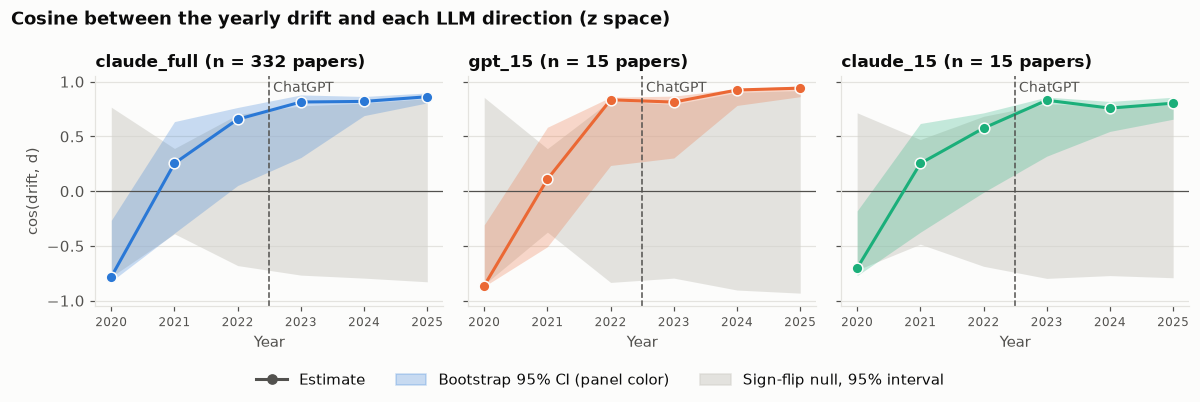

In [5]:
plot_by_direction("cos", "z", "cos(drift, d)", "Cosine between the yearly drift and each LLM direction (z space)", (-1.05, 1.05), "cos_z.png")

### How far along the LLM direction has each year moved?

`proj_y` is the distance along the direction: 0 is REF's human style and 1 is the LLM's style. The y-axis is cut, because the sign-flip band is much wider than the estimates; a note in the panel gives its full reach.

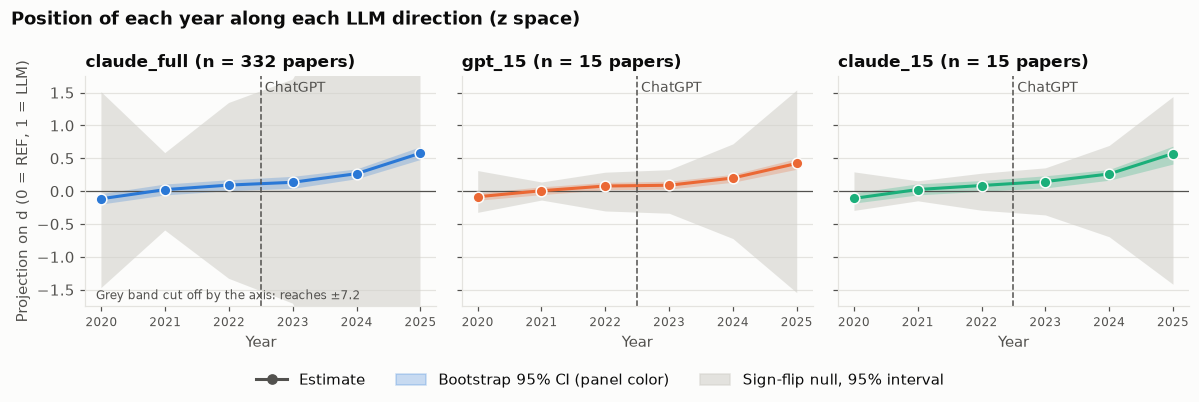

In [6]:
plot_by_direction("proj", "z", "Projection on d (0 = REF, 1 = LLM)", "Position of each year along each LLM direction (z space)", (-1.75, 1.75), "proj_z.png")

**The 15-paper results.** `gpt_15` and `claude_15` come from n = 15 papers, so read them with care: the null band, not the point estimate, says whether anything is detectable.

Reading the band, for all three directions: a sign flip does not remove a strong real direction, because the signs of a finite sample do not cancel exactly. Each flipped average keeps `±d` plus noise, so the `cos` band grows with the size of the observed `cos`. For `proj`, the division by `‖d_null‖²` uses a null direction far shorter than the real `d`, so the band is on a different scale from the estimates, and it is widest for `claude_full`, whose null directions are the shortest. An estimate inside the band is therefore not evidence of no drift.

In [7]:
wanted = drift[(drift.space == "z") & (drift.year >= 2023)]
display(wanted.set_index(["direction", "year"])[["cos", "cos_lo", "cos_hi", "null_cos_lo", "null_cos_hi", "proj", "proj_lo", "proj_hi", "null_proj_lo", "null_proj_hi"]].round(3))
agreement.round(3)

cos  cos_lo  cos_hi  null_cos_lo  null_cos_hi   proj  \
direction   year                                                           
claude_full 2023  0.814   0.307   0.879       -0.767        0.779  0.136   
            2024  0.820   0.690   0.865       -0.794        0.804  0.267   
            2025  0.863   0.806   0.897       -0.828        0.846  0.579   
gpt_15      2023  0.814   0.303   0.868       -0.794        0.792  0.090   
            2024  0.924   0.783   0.935       -0.903        0.902  0.201   
            2025  0.941   0.863   0.961       -0.931        0.919  0.422   
claude_15   2023  0.830   0.319   0.859       -0.796        0.799  0.147   
            2024  0.759   0.546   0.819       -0.771        0.774  0.262   
            2025  0.803   0.657   0.858       -0.791        0.788  0.573   

                  proj_lo  proj_hi  null_proj_lo  null_proj_hi  
direction   year                                                
claude_full 2023    0.043    0.226        -1.711         1.699  
            2024    0.190    0.339        -3.369         3.317  
            2025    0.483    0.679        -7.248         7.022  
gpt_15      2023    0.031    0.151        -0.336         0.327  
            2024    0.136    0.256        -0.721         0.720  
            2025    0.334    0.497        -1.544         1.542  
claude_15   2023    0.049    0.234        -0.362         0.355  
            2024    0.167    0.330        -0.694         0.696  
            2025    0.413    0.685        -1.417         1.440

,space,direction_a,direction_b,n_papers_a,n_papers_b,n_papers_shared,cos,cos_lo,cos_hi,null_cos_lo,null_cos_hi
0,z,claude_full,gpt_15,332,15,15,0.813,0.754,0.846,-0.640,0.762
1,z,claude_full,claude_15,332,15,15,0.967,0.879,0.967,-0.616,0.815
2,z,gpt_15,claude_15,15,15,15,0.783,0.672,0.850,0.279,0.884
3,whitened,claude_full,gpt_15,332,15,15,0.613,0.495,0.682,-0.354,0.571
4,whitened,claude_full,claude_15,332,15,15,0.925,0.778,0.924,-0.351,0.670
5,whitened,gpt_15,claude_15,15,15,15,0.640,0.548,0.730,0.350,0.825


The table above gives the agreement between directions. Here, a paper keeps its random sign in both directions, so the null keeps what a pair shares by construction: `gpt_15` and `claude_15` are measured against the same 15 human abstracts, and the 15 papers are part of `claude_full`.

### Which features shift, per source and year?

Mean z-score of each feature per (year, source), that is, its shift in REF SDs. Red is above REF's mean and blue is below. The ChatGPT panel has n = 5 per year, so a large value there can be noise.

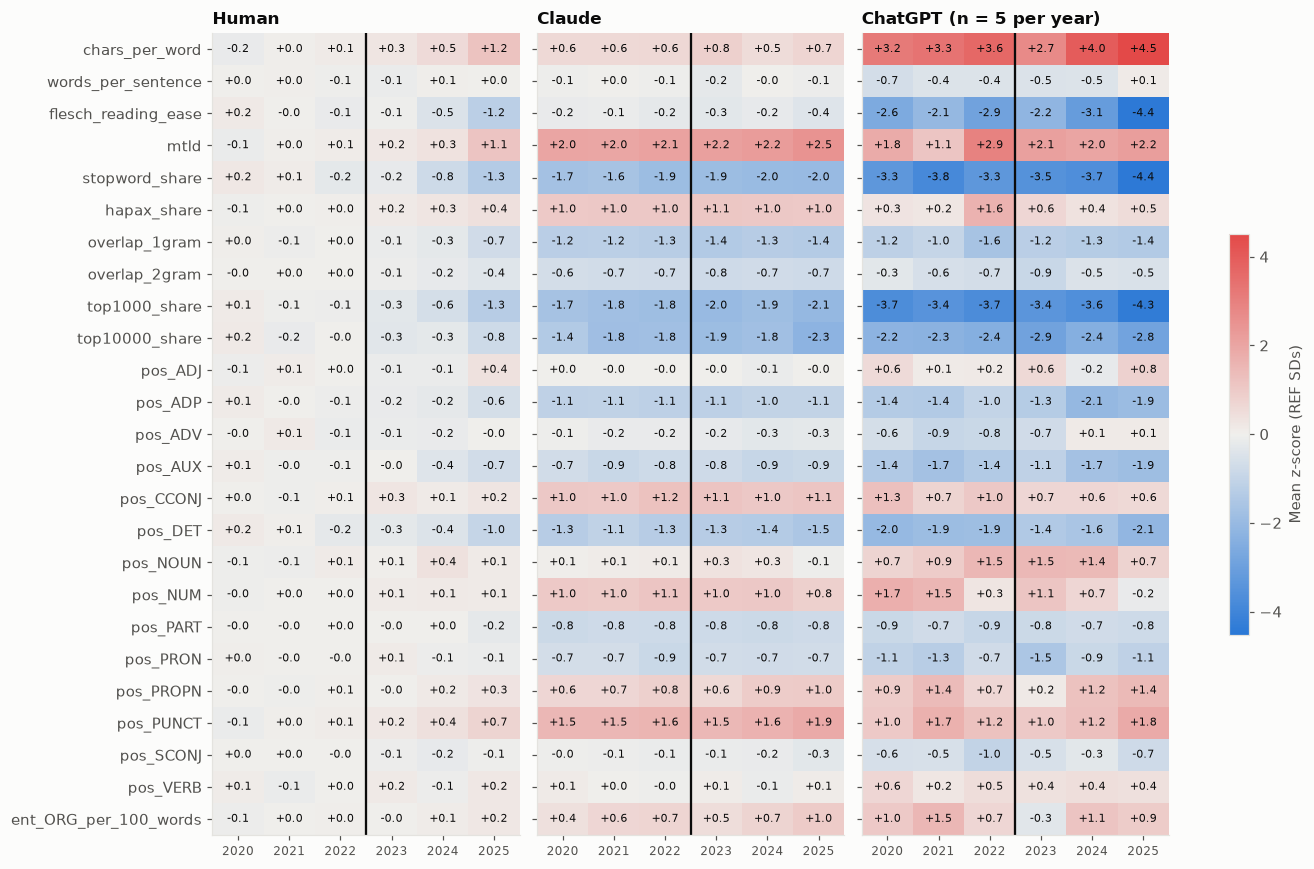

In [8]:
means = tables["group_feature_means"]
sources = {HUMAN: "Human", CLAUDE: "Claude", GPT: "ChatGPT (n = 5 per year)"}
grids = {s: means[means.source == s].set_index("year")[list(FEATURES)].T for s in sources}
limit = max(np.abs(g.to_numpy()).max() for g in grids.values())

fig, axes = plt.subplots(1, 3, figsize=(13, 8), sharey=True)
for ax, (source, name) in zip(axes, sources.items()):
    grid = grids[source]
    image = ax.imshow(grid.to_numpy(), cmap=DIVERGING, vmin=-limit, vmax=limit, aspect="auto")
    ax.set_xticks(range(len(grid.columns)), grid.columns, fontsize=8)
    ax.set_yticks(range(len(grid.index)), grid.index)
    ax.grid(False)
    for (r, c), value in np.ndenumerate(grid.to_numpy()):
        ax.text(c, r, f"{value:+.1f}", ha="center", va="center", fontsize=7, color=TEXT)
    ax.axvline(2.5, color=TEXT, linewidth=1.5)
    ax.set_title(name)
fig.tight_layout()
fig.colorbar(image, ax=axes, shrink=0.5, label="Mean z-score (REF SDs)")
fig.savefig(FIGURES / "group_feature_means.png", dpi=160, bbox_inches="tight")
plt.show()

### How close is each paper's LLM abstract to its human abstract?

Cosine similarity and Euclidean distance between the two versions of a paper, averaged by year with a bootstrap 95% CI. The line uses every paper. The offset points use only the 30 papers with a ChatGPT abstract (n = 5 per year), so compare human vs ChatGPT with the aqua points, not with the line.

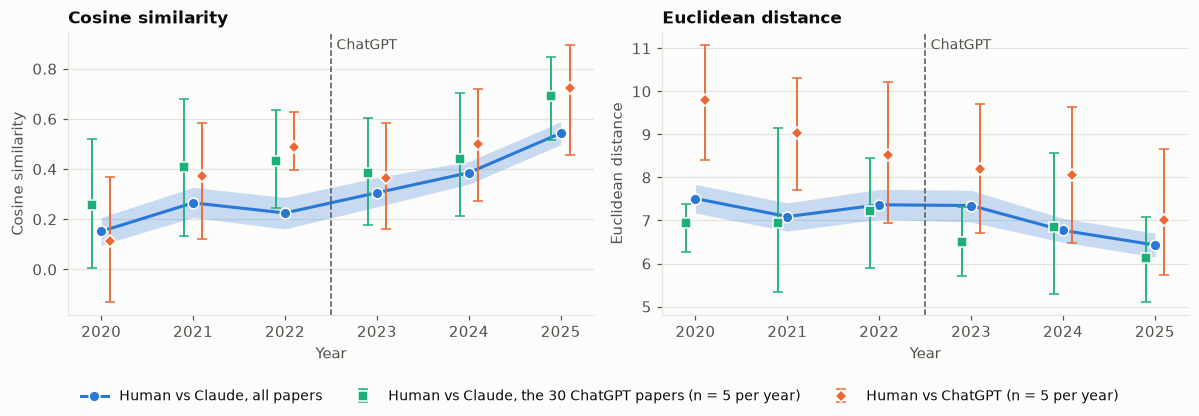

In [9]:
plot_similarity("z", "paired_similarity_z.png")

### Robustness: the whitened space

The same plots after removing the correlations between features. One caveat: REF's smallest eigenvalue is close to 0, so whitening multiplies that component by a large factor. Its value is printed below.

Smallest eigenvalues of REF's PCA: [0.1198 0.0689 0.0026]


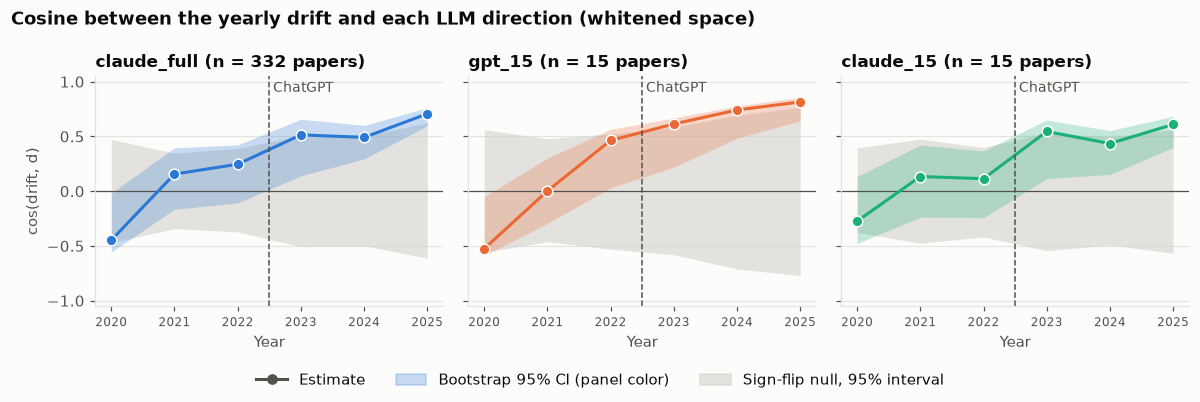

In [10]:
print("Smallest eigenvalues of REF's PCA:", prep.eigenvalues[-3:].round(4))
plot_by_direction("cos", "whitened", "cos(drift, d)", "Cosine between the yearly drift and each LLM direction (whitened space)", (-1.05, 1.05), "cos_whitened.png")

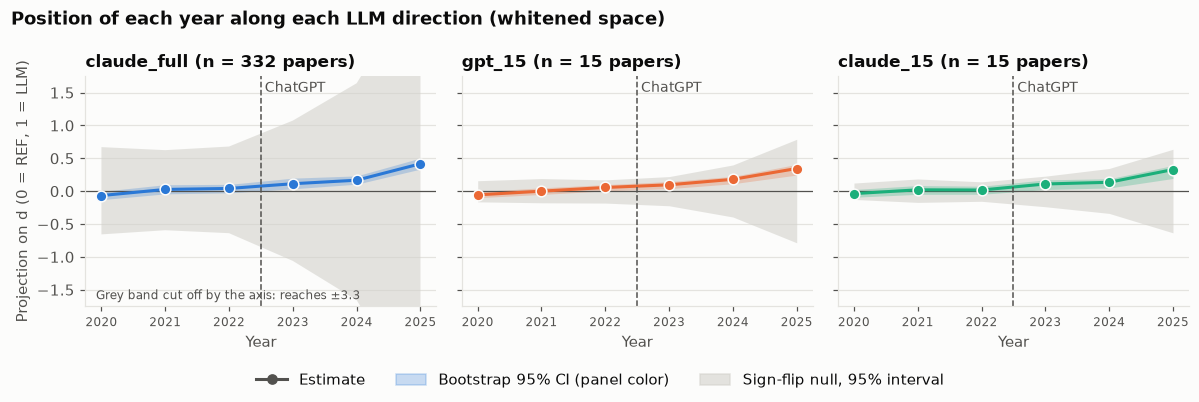

In [11]:
plot_by_direction("proj", "whitened", "Projection on d (0 = REF, 1 = LLM)", "Position of each year along each LLM direction (whitened space)", (-1.75, 1.75), "proj_whitened.png")

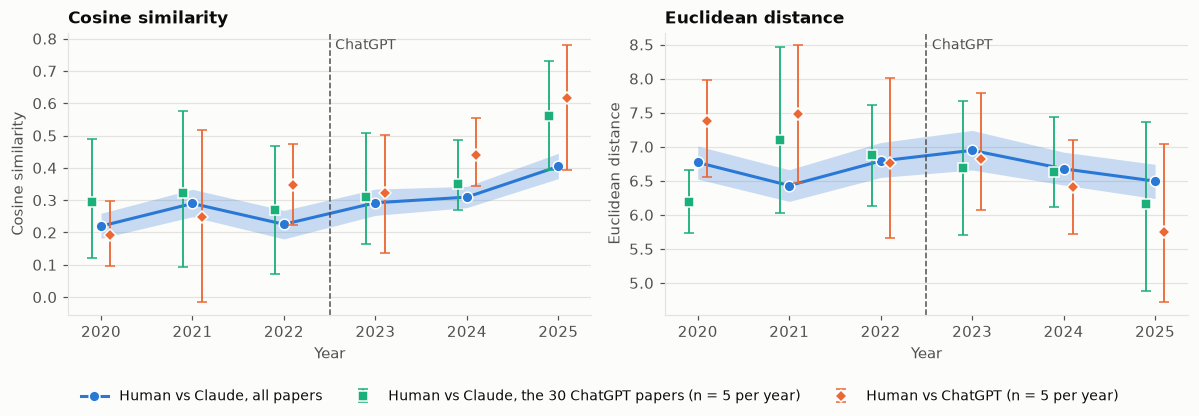

In [12]:
plot_similarity("whitened", "paired_similarity_whitened.png")